# Interpretability 4: Feature attribution

How to determine the importance of features? This is known as feature attribution. This notebook shows how to get feature scores in KANs.

In [1]:
from sympy import *
import torch
import matplotlib.pyplot as plt
from xkan import KANNetwork, create_dataset, fit
from xkan.interp import attribute, feature_score, prune, prune_input
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# let's construct a dataset
f = lambda x: x[:,0]**2 + 0.3*x[:,1] + 0.1*x[:,2]**3 + 0.0*x[:,3]
train, test = create_dataset(f, n_var=4, device=device)

input_vars = [r'$x_'+str(i)+'$' for i in range(4)]

model = KANNetwork([4,5,1], device=device)
history = fit(model, train, test, steps=40, lamb=0.001)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

cuda


train RMSE 0.009909762303701481 test RMSE 0.009914170321656231


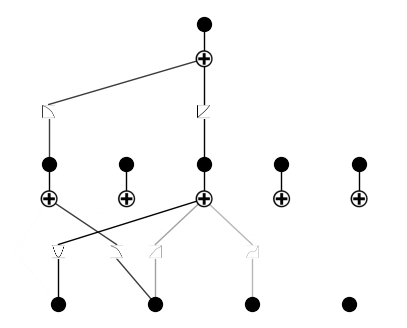

In [2]:
plot(model, train['x']);

get feature score (for input variables)

In [3]:
feature_score(model, train['x'])

tensor([0.8584, 0.4679, 0.0983, 0.0022], device='cuda:0')

Inspect how hidden nodes depend on features

tensor([0.8558, 0.1282, 0.0971, 0.0011], device='cuda:0')

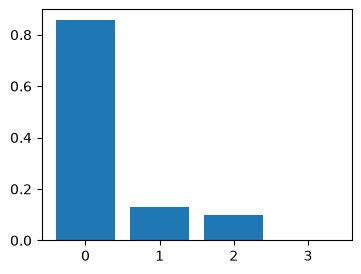

In [4]:
def plot_node_attribution(model, x, l, i):
    # the scores of the inputs for node i of node layer l, as a bar chart
    score = attribute(model, x, layer=l).node_all[0][i]
    in_dim = model.width_in[0]
    plt.figure(figsize=(1*in_dim, 3))
    plt.bar(range(in_dim), score.cpu().detach().numpy())
    plt.xticks(range(in_dim))
    return score

# the 2nd neuron (index start from 0) in the 1st layer
plot_node_attribution(model, train['x'], 1, 2)

tensor([8.1582e-06, 1.3000e-05, 3.1928e-05, 1.4424e-05], device='cuda:0')

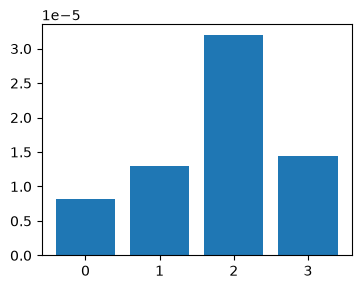

In [5]:
# the 3nd neuron (index start from 0) in the 1st layer
# note the y axis scale is really small
plot_node_attribution(model, train['x'], 1, 3)

prune inputs

keep: [0, 1, 2]


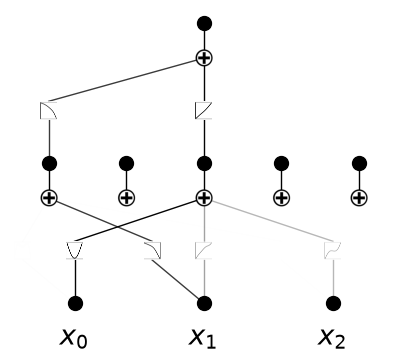

In [6]:
model = prune_input(model, train['x'])
print('keep:', model.input_id.tolist())
plot(model, train['x'], in_vars=input_vars);

Let's consider a high-dimensional case. In the case of many inputs but only few are important, the users may want to prune input otherwise too many inputs make interpretable hard.

In [7]:
import copy

# let's construct a dataset
n_var = 100

def f(x):
    y = 0
    for i in range(n_var):
        # exponential decay
        y += x[:,[i]]**2*0.5**i
    return y
        
train, test = create_dataset(f, n_var=n_var, device=device)

input_vars = [r'$x_{'+str(i)+'}$' for i in range(n_var)]

model = KANNetwork([n_var,10,10,1], seed=2, device=device)
history = fit(model, train, test, steps=50, lamb=1e-3)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
trained = copy.deepcopy(model)  # xkan 1.0 keeps no history: a copy of the trained network to come back to

train RMSE 0.014907039886534032 test RMSE 0.027359697042851374


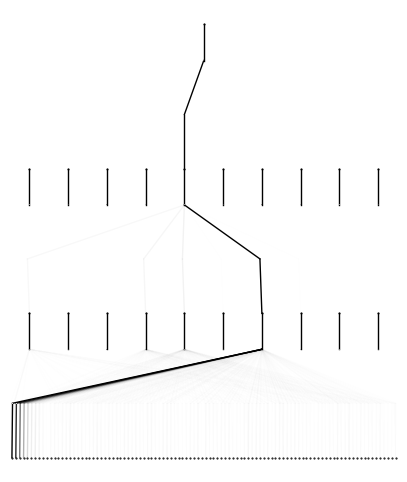

In [8]:
plot(model, train['x']);

In [9]:
model = copy.deepcopy(trained)

Text(0, 0.5, 'feature attribution score')

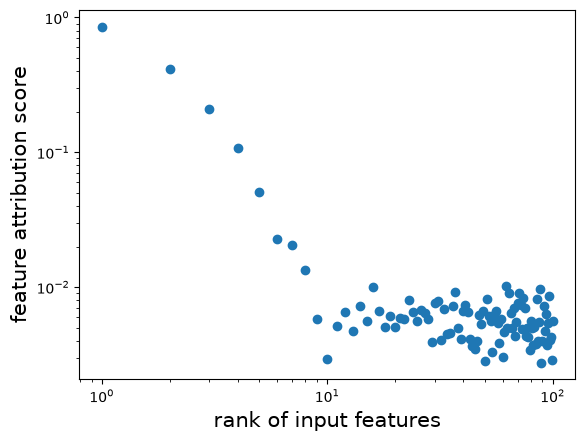

In [10]:
import numpy as np

plt.scatter(np.arange(n_var)+1, feature_score(model, train['x']).cpu().detach().numpy())
plt.xscale('log')
plt.yscale('log')
plt.xlabel('rank of input features', fontsize=15)
plt.ylabel('feature attribution score', fontsize=15)

Since there are 100D inputs, it's very time consuming to plot the whole diagram and hard to read anything meaningful out of the diagram. So we want to prune the network first (including pruning hidden nodes and pruning inputs) and then plot it.

keep: [0, 1, 2, 3, 4] width: [[5, 0], [1, 0], [1, 0], [1, 0]]


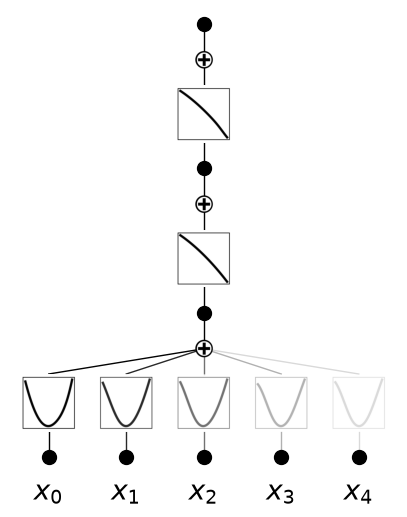

In [11]:
model = prune(model, train['x'])
model = prune_input(model, train['x'], threshold=3e-2)
print('keep:', model.input_id.tolist(), 'width:', model.width)
plot(model, train['x'], in_vars=input_vars);